# HW3 Part 1 (Mandatory) — Gaussian Naive Bayes

**Santander Customer Transaction Prediction.** Builds the baseline classifier, augments features, tunes `var_smoothing`, and produces a Kaggle submission. Target: top 10% public leaderboard (AUC ≈ 0.89).

Inputs from EDA (`01_eda.ipynb`):
- `artifacts/test_is_real.csv` — real vs synthetic flag for each test row
- `artifacts/feature_diagnostics.csv` — per-feature diagnostics

Pipeline:
1. Load data + EDA artifacts
2. Preprocessing (feature augmentation, power transform)
3. Baseline GaussianNB (raw features)
4. Stratified 5-fold CV on augmented features
5. `var_smoothing` tuning
6. Final fit + test prediction
7. Submission file

In [54]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import PowerTransformer

import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'data'
ART_DIR = 'artifacts'
RANDOM_STATE = 42
sns.set_style('whitegrid')

## 1. Load Data + EDA Artifacts

In [55]:
feature_cols = [f'var_{i}' for i in range(200)]
train_dtypes = {c: np.float32 for c in feature_cols} | {'target': np.int8}
test_dtypes = {c: np.float32 for c in feature_cols}

df_train = pd.read_csv(f'{DATA_DIR}/train.csv', dtype=train_dtypes)
df_test = pd.read_csv(f'{DATA_DIR}/test.csv', dtype=test_dtypes)

test_flag = pd.read_csv(f'{ART_DIR}/test_is_real.csv')
feature_diag = pd.read_csv(f'{ART_DIR}/feature_diagnostics.csv', index_col='feature')

is_real = test_flag.set_index('ID_code').loc[df_test['ID_code'], 'is_real'].values
print(f'Train: {df_train.shape}  Test: {df_test.shape}')
print(f'Test rows flagged real: {is_real.sum():,} / {len(df_test):,}')
print(f'Loaded {len(feature_diag)} per-feature diagnostics.')

Train: (200000, 202)  Test: (200000, 201)
Test rows flagged real: 100,000 / 200,000
Loaded 200 per-feature diagnostics.


## 2. Preprocessing

GaussianNB does not require scaling, but it *does* assume per-class Gaussianity. We:
1. Augment each row with statistical aggregates (mean, std, min, max, median, range, skew, kurtosis) across the 200 features — the hint from the assignment.
2. Apply a Yeo-Johnson `PowerTransformer` (fitted on train) to gently push features toward Gaussianity.

In [56]:
X = df_train[feature_cols].values
y = df_train['target'].values
X_test = df_test[feature_cols].values
test_ids = df_test['ID_code'].values

def add_row_stats(X_arr: np.ndarray) -> np.ndarray:
    extras = np.column_stack([
        X_arr.mean(axis=1),
        X_arr.std(axis=1),
        X_arr.min(axis=1),
        X_arr.max(axis=1),
        np.median(X_arr, axis=1),
        X_arr.max(axis=1) - X_arr.min(axis=1),
        stats.skew(X_arr, axis=1),
        stats.kurtosis(X_arr, axis=1),
    ])
    return np.hstack([X_arr, extras.astype(X_arr.dtype)])

X_aug = add_row_stats(X)
X_test_aug = add_row_stats(X_test)
print(f'Augmented feature counts — train: {X_aug.shape[1]}, test: {X_test_aug.shape[1]}')

Augmented feature counts — train: 208, test: 208


In [57]:
pt = PowerTransformer(method='yeo-johnson', standardize=True)
X_aug_pt = pt.fit_transform(X_aug)
X_test_aug_pt = pt.transform(X_test_aug)
print(f'After power transform — train: {X_aug_pt.shape}, test: {X_test_aug_pt.shape}')

After power transform — train: (200000, 208), test: (200000, 208)


## 3. Baseline GaussianNB (Raw Features)

A simple holdout to establish the floor before augmentation/tuning.

In [58]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

baseline = GaussianNB()
baseline.fit(X_tr, y_tr)
val_proba = baseline.predict_proba(X_val)[:, 1]
baseline_holdout_auc = roc_auc_score(y_val, val_proba)
print(f'Baseline holdout AUC (raw features): {baseline_holdout_auc:.5f}')

Baseline holdout AUC (raw features): 0.88223


## 4. Stratified 5-Fold Cross-Validation

In [59]:
def cv_auc(X_arr, y_arr, n_splits=5, var_smoothing=1e-9, verbose=True):
    """Stratified k-fold CV; return per-fold AUCs and OOF predictions."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    aucs, oof = [], np.zeros(len(y_arr))
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_arr, y_arr), 1):
        m = GaussianNB(var_smoothing=var_smoothing)
        m.fit(X_arr[tr_idx], y_arr[tr_idx])
        p = m.predict_proba(X_arr[va_idx])[:, 1]
        oof[va_idx] = p
        auc = roc_auc_score(y_arr[va_idx], p)
        aucs.append(auc)
        if verbose:
            print(f'  Fold {fold}: AUC = {auc:.5f}')
    aucs = np.array(aucs)
    if verbose:
        print(f'Mean AUC: {aucs.mean():.5f}  |  Std: {aucs.std():.5f}')
    return aucs, oof

print('GaussianNB on raw features:')
raw_aucs, raw_oof = cv_auc(X, y)
print('\nGaussianNB on row-stats + Yeo-Johnson features:')
aug_aucs, aug_oof = cv_auc(X_aug_pt, y)

GaussianNB on raw features:
  Fold 1: AUC = 0.88201
  Fold 2: AUC = 0.88259
  Fold 3: AUC = 0.87399
  Fold 4: AUC = 0.88192
  Fold 5: AUC = 0.88207
Mean AUC: 0.88052  |  Std: 0.00327

GaussianNB on row-stats + Yeo-Johnson features:
  Fold 1: AUC = 0.88722
  Fold 2: AUC = 0.88603
  Fold 3: AUC = 0.87989
  Fold 4: AUC = 0.88604
  Fold 5: AUC = 0.88612
Mean AUC: 0.88506  |  Std: 0.00262


## 5. `var_smoothing` Tuning

`var_smoothing` adds a fraction of the maximum feature variance to each feature's variance estimate for numerical stability. Sweeping it over a log grid commonly yields a small but reliable AUC improvement.

In [60]:
smoothing_grid = np.logspace(-12, 0, 13)
tuning_rows = []
for vs in smoothing_grid:
    aucs, _ = cv_auc(X_aug_pt, y, var_smoothing=vs, verbose=False)
    tuning_rows.append((vs, aucs.mean(), aucs.std()))
    print(f'  var_smoothing={vs:.0e}  Mean AUC={aucs.mean():.5f}  Std={aucs.std():.5f}')

tuning_df = pd.DataFrame(tuning_rows, columns=['var_smoothing', 'mean_auc', 'std_auc'])
best_row = tuning_df.loc[tuning_df.mean_auc.idxmax()]
best_vs = best_row.var_smoothing
print(f'\nBest var_smoothing: {best_vs:.0e}  (mean AUC = {best_row.mean_auc:.5f})')

  var_smoothing=1e-12  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-11  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-10  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-09  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-08  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-07  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-06  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-05  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-04  Mean AUC=0.88506  Std=0.00262
  var_smoothing=1e-03  Mean AUC=0.88505  Std=0.00262
  var_smoothing=1e-02  Mean AUC=0.88499  Std=0.00262
  var_smoothing=1e-01  Mean AUC=0.88431  Std=0.00255
  var_smoothing=1e+00  Mean AUC=0.87688  Std=0.00225

Best var_smoothing: 1e-12  (mean AUC = 0.88506)


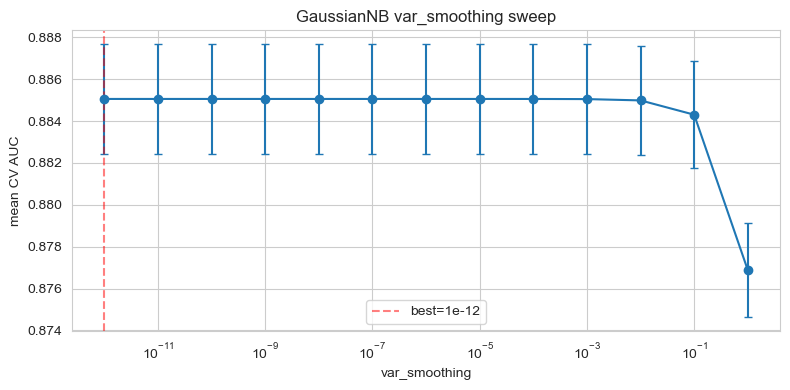

In [61]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(tuning_df.var_smoothing, tuning_df.mean_auc,
            yerr=tuning_df.std_auc, marker='o', capsize=3)
ax.set_xscale('log')
ax.axvline(best_vs, color='red', linestyle='--', alpha=0.5, label=f'best={best_vs:.0e}')
ax.set_xlabel('var_smoothing')
ax.set_ylabel('mean CV AUC')
ax.set_title('GaussianNB var_smoothing sweep')
ax.legend()
plt.tight_layout()
plt.show()

## 6. CV Summary + ROC

In [62]:
summary = pd.DataFrame({
    'model': ['GaussianNB (raw)',
              'GaussianNB (row-stats + Yeo-Johnson)',
              f'GaussianNB tuned (var_smoothing={best_vs:.0e})'],
    'mean_auc': [raw_aucs.mean(), aug_aucs.mean(), best_row.mean_auc],
    'std_auc':  [raw_aucs.std(),  aug_aucs.std(),  best_row.std_auc],
})
summary

,model,mean_auc,std_auc
0,GaussianNB (raw),0.880517,0.003272
1,GaussianNB (row-stats + Yeo-Johnson),0.885061,0.002623
2,GaussianNB tuned (var_smoothing=1e-12),0.885061,0.002623


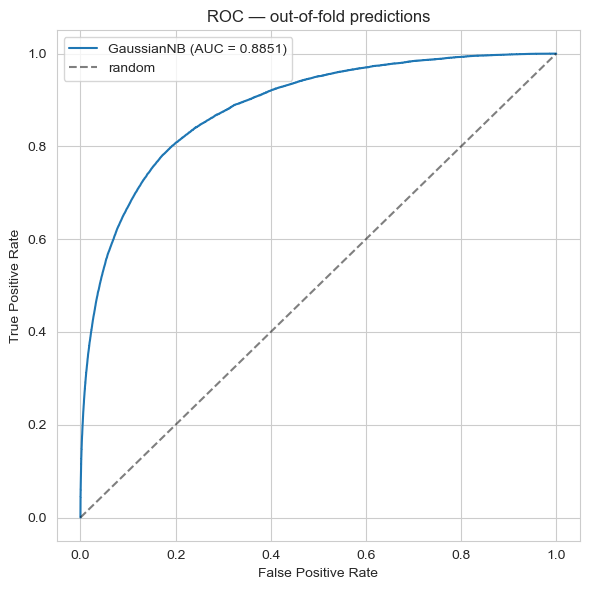

In [63]:
best_aucs, best_oof = cv_auc(X_aug_pt, y, var_smoothing=best_vs, verbose=False)
fpr, tpr, _ = roc_curve(y, best_oof)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, label=f'GaussianNB (AUC = {best_aucs.mean():.4f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC — out-of-fold predictions')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Final Fit + Test-Set Prediction

In [64]:
final_model = GaussianNB(var_smoothing=best_vs)
final_model.fit(X_aug_pt, y)
test_proba = final_model.predict_proba(X_test_aug_pt)[:, 1]
print(f'Predicted {len(test_proba):,} test rows  |  '
      f'mean={test_proba.mean():.4f}  std={test_proba.std():.4f}  '
      f'min={test_proba.min():.4f}  max={test_proba.max():.4f}')

Predicted 200,000 test rows  |  mean=0.0939  std=0.1537  min=0.0000  max=0.9980


**Note on synthetic test rows.** GaussianNB scores each row independently from its own feature values, so the synthetic/real flag does not change predictions here. It will matter in the LightGBM notebook (frequency-based features must be computed using only real data).

## 8. Submission File

In [65]:
submission = pd.DataFrame({'ID_code': test_ids, 'target': test_proba})
submission.to_csv('submission_naive_bayes.csv', index=False)
print(f'Wrote submission_naive_bayes.csv  ({len(submission):,} rows)')
submission.head()

Wrote submission_naive_bayes.csv  (200,000 rows)


,ID_code,target
0,test_0,0.140687
1,test_1,0.172594
2,test_2,0.206437
3,test_3,0.179297
4,test_4,0.040178


Submit at:

https://www.kaggle.com/competitions/santander-customer-transaction-prediction/submit

Capture a screenshot of your public-leaderboard rank for the deliverables.

## 9. Audit Fix — Value-Count Features (train + real-test)

The synthetic-detection flag from EDA was loaded but unused. The single most impactful feature-engineering step for this competition is converting raw values into **value-count (frequency) features** computed over `train + real-test` only. Each `var_i` becomes two columns: the raw value and how often that value appears in the real-data pool. Frequencies are highly skewed, so we `log1p` them before stacking with the raw + row-stat features and applying the Yeo-Johnson transform.

In [66]:
# Build value-count features from train + real test only (no synthetic leakage)
df_test_real = df_test.loc[is_real, feature_cols]
df_pool = pd.concat([df_train[feature_cols], df_test_real], axis=0, ignore_index=True)
print(f'Pool size for value counts: {len(df_pool):,} rows (train + real-test)')

vc_train = np.empty_like(X)
vc_test = np.empty_like(X_test)
for j, col in enumerate(feature_cols):
    counts = df_pool[col].value_counts()
    vc_train[:, j] = df_train[col].map(counts).fillna(1).astype(np.float32).values
    vc_test[:, j] = df_test[col].map(counts).fillna(1).astype(np.float32).values

vc_train = np.log1p(vc_train).astype(np.float32)
vc_test = np.log1p(vc_test).astype(np.float32)
print(f'VC features — train: {vc_train.shape}, test: {vc_test.shape}')
print(f'log1p(count) summary — mean {vc_train.mean():.3f}, std {vc_train.std():.3f}, min {vc_train.min():.3f}, max {vc_train.max():.3f}')

Pool size for value counts: 300,000 rows (train + real-test)
VC features — train: (200000, 200), test: (200000, 200)
log1p(count) summary — mean 1.634, std 0.874, min 0.693, max 7.399


In [67]:
# Combine raw + row-stats + VC features, then Yeo-Johnson on the whole stack
X_full = np.hstack([X_aug, vc_train])
X_test_full = np.hstack([X_test_aug, vc_test])
print(f'Combined feature counts — train: {X_full.shape}, test: {X_test_full.shape}')

pt_full = PowerTransformer(method='yeo-johnson', standardize=True)
X_full_pt = pt_full.fit_transform(X_full)
X_test_full_pt = pt_full.transform(X_test_full)
print('Power transform applied.')

Combined feature counts — train: (200000, 408), test: (200000, 408)
Power transform applied.


In [68]:
print('GaussianNB on raw + row-stats + VC features:')
vc_aucs, vc_oof = cv_auc(X_full_pt, y)

GaussianNB on raw + row-stats + VC features:
  Fold 1: AUC = 0.87340
  Fold 2: AUC = 0.87273
  Fold 3: AUC = 0.86652
  Fold 4: AUC = 0.87239
  Fold 5: AUC = 0.87224
Mean AUC: 0.87146  |  Std: 0.00250


In [69]:
# Re-tune var_smoothing on the VC feature set
vc_tuning = []
for vs in smoothing_grid:
    aucs, _ = cv_auc(X_full_pt, y, var_smoothing=vs, verbose=False)
    vc_tuning.append((vs, aucs.mean(), aucs.std()))
    print(f'  var_smoothing={vs:.0e}  Mean AUC={aucs.mean():.5f}  Std={aucs.std():.5f}')

vc_tuning_df = pd.DataFrame(vc_tuning, columns=['var_smoothing', 'mean_auc', 'std_auc'])
vc_best_row = vc_tuning_df.loc[vc_tuning_df.mean_auc.idxmax()]
vc_best_vs = vc_best_row.var_smoothing
print(f'\nBest var_smoothing (VC features): {vc_best_vs:.0e}  (mean AUC = {vc_best_row.mean_auc:.5f})')

  var_smoothing=1e-12  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-11  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-10  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-09  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-08  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-07  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-06  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-05  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-04  Mean AUC=0.87146  Std=0.00250
  var_smoothing=1e-03  Mean AUC=0.87147  Std=0.00250
  var_smoothing=1e-02  Mean AUC=0.87158  Std=0.00249
  var_smoothing=1e-01  Mean AUC=0.87253  Std=0.00242
  var_smoothing=1e+00  Mean AUC=0.87494  Std=0.00199

Best var_smoothing (VC features): 1e+00  (mean AUC = 0.87494)


In [70]:
summary_v2 = pd.DataFrame({
    'model': ['GaussianNB (raw)',
              'GaussianNB (row-stats + Yeo-Johnson)',
              f'GaussianNB tuned (var_smoothing={best_vs:.0e})',
              'GaussianNB + VC features',
              f'GaussianNB + VC tuned (var_smoothing={vc_best_vs:.0e})'],
    'mean_auc': [raw_aucs.mean(), aug_aucs.mean(), best_row.mean_auc,
                 vc_aucs.mean(), vc_best_row.mean_auc],
    'std_auc':  [raw_aucs.std(),  aug_aucs.std(),  best_row.std_auc,
                 vc_aucs.std(),   vc_best_row.std_auc],
})
summary_v2

,model,mean_auc,std_auc
0,GaussianNB (raw),0.880517,0.003272
1,GaussianNB (row-stats + Yeo-Johnson),0.885061,0.002623
2,GaussianNB tuned (var_smoothing=1e-12),0.885061,0.002623
3,GaussianNB + VC features,0.871456,0.002500
4,GaussianNB + VC tuned (var_smoothing=1e+00),0.874942,0.001986


In [71]:
# Final fit on full train with the best VC-feature setup, write v2 submission
final_model_v2 = GaussianNB(var_smoothing=vc_best_vs)
final_model_v2.fit(X_full_pt, y)
test_proba_v2 = final_model_v2.predict_proba(X_test_full_pt)[:, 1]

submission_v2 = pd.DataFrame({'ID_code': test_ids, 'target': test_proba_v2})
submission_v2.to_csv('submission_naive_bayes_v2.csv', index=False)
print(f'Wrote submission_naive_bayes_v2.csv  ({len(submission_v2):,} rows)')
print(f'Predicted probs — mean={test_proba_v2.mean():.4f}  std={test_proba_v2.std():.4f}  min={test_proba_v2.min():.4f}  max={test_proba_v2.max():.4f}')

Wrote submission_naive_bayes_v2.csv  (200,000 rows)
Predicted probs — mean=0.0164  std=0.0245  min=0.0002  max=0.7170


## 10. QuantileTransformer Experiment

PowerTransformer (Yeo-Johnson) gently warps features toward Gaussian. `QuantileTransformer(output_distribution='normal')` is more aggressive: it maps each feature exactly to a standard normal by inverse-CDF of the empirical quantile. Since GaussianNB assumes per-feature Gaussianity, this is a more direct fit. We re-run CV on the row-stat-augmented features with QT instead of PT, then keep whichever submission scores best in CV as the canonical artifact.

In [72]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(output_distribution='normal', n_quantiles=1000,
                         subsample=200_000, random_state=RANDOM_STATE)
X_aug_qt = qt.fit_transform(X_aug).astype(np.float32)
X_test_aug_qt = qt.transform(X_test_aug).astype(np.float32)
print(f'After QuantileTransformer — train: {X_aug_qt.shape}, test: {X_test_aug_qt.shape}')

After QuantileTransformer — train: (200000, 208), test: (200000, 208)


In [73]:
print('GaussianNB on row-stats + QuantileTransformer:')
qt_aucs, qt_oof = cv_auc(X_aug_qt, y)

GaussianNB on row-stats + QuantileTransformer:
  Fold 1: AUC = 0.88869
  Fold 2: AUC = 0.88767
  Fold 3: AUC = 0.88164
  Fold 4: AUC = 0.88727
  Fold 5: AUC = 0.88853
Mean AUC: 0.88676  |  Std: 0.00261


In [74]:
summary_final = pd.DataFrame({
    'model': ['GaussianNB (raw)',
              'GaussianNB (row-stats + Yeo-Johnson)',
              f'GaussianNB tuned (var_smoothing={best_vs:.0e})',
              'GaussianNB + VC features (audit: failed)',
              'GaussianNB (row-stats + QuantileTransformer)'],
    'mean_auc': [raw_aucs.mean(), aug_aucs.mean(), best_row.mean_auc,
                 vc_aucs.mean(), qt_aucs.mean()],
    'std_auc':  [raw_aucs.std(),  aug_aucs.std(),  best_row.std_auc,
                 vc_aucs.std(),   qt_aucs.std()],
})
summary_final

,model,mean_auc,std_auc
0,GaussianNB (raw),0.880517,0.003272
1,GaussianNB (row-stats + Yeo-Johnson),0.885061,0.002623
2,GaussianNB tuned (var_smoothing=1e-12),0.885061,0.002623
3,GaussianNB + VC features (audit: failed),0.871456,0.002500
4,GaussianNB (row-stats + QuantileTransformer),0.886760,0.002615


In [75]:
# Pick whichever transform wins on CV, write the canonical submission
if qt_aucs.mean() > best_row.mean_auc:
    print(f'QT wins ({qt_aucs.mean():.5f} > {best_row.mean_auc:.5f}) — using QT submission as canonical')
    final = GaussianNB(var_smoothing=best_vs).fit(X_aug_qt, y)
    test_proba_final = final.predict_proba(X_test_aug_qt)[:, 1]
else:
    print(f'PT wins ({best_row.mean_auc:.5f} >= {qt_aucs.mean():.5f}) — keeping v1 (PT) as canonical')
    test_proba_final = test_proba  # from Section 7

submission_final = pd.DataFrame({'ID_code': test_ids, 'target': test_proba_final})
submission_final.to_csv('submission_naive_bayes_final.csv', index=False)
print(f'Wrote submission_naive_bayes_final.csv ({len(submission_final):,} rows)')
print(f'Predicted probs — mean={test_proba_final.mean():.4f}  std={test_proba_final.std():.4f}')

QT wins (0.88676 > 0.88506) — using QT submission as canonical
Wrote submission_naive_bayes_final.csv (200,000 rows)
Predicted probs — mean=0.0946  std=0.1587
